In [28]:
data_60

,Hot Water Outlet Temperature (C),Hot Water Unmet Demand (kWh),Water Heating Electric Power (kWh),Water Heating Heat Pump COP (-),Water Heating Mode,T_WH1,T_WH3,T_WH6,T_WH10,T_WH12,Setpoints,Draw Data
0,59.430630,0.0,0.000017,3.125657,Off,59.430630,59.437452,59.437452,59.437452,59.430630,60,0.0
1,59.416827,0.0,0.000017,3.126124,Off,59.416827,59.430461,59.430461,59.430461,59.416827,60,0.0
2,59.403035,0.0,0.000017,3.126591,Off,59.403035,59.423471,59.423471,59.423471,59.403035,60,0.0
3,59.389254,0.0,0.000017,3.127058,Off,59.389254,59.416482,59.416482,59.416482,59.389254,60,0.0
4,59.375483,0.0,0.000017,3.127526,Off,59.375483,59.409495,59.409495,59.409495,59.375483,60,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1433,59.618983,0.0,0.000017,3.909165,Off,59.618983,59.786934,59.837821,46.577128,16.312329,60,0.0
1434,59.605186,0.0,0.000017,3.909703,Off,59.605186,59.779718,59.830724,46.571111,16.331304,60,0.0
1435,59.736825,0.0,0.000017,3.910241,Off,59.736825,59.582279,59.823628,46.565087,16.350246,60,0.0
1436,59.722909,0.0,0.000017,3.910778,Off,59.722909,59.575478,59.816532,46.559055,16.369155,60,0.0


In [3]:
#Get numeric comparison b/w 12 node and data_60
import pandas as pd
site = 'sample' 
data_60 = pd.read_csv(f"output_site_{site}_151(L)_60_120V.csv")
data_12_node = pd.read_csv(f"output_site_{site}_bisection_perfect_12_120V.csv")
data_2_node = pd.read_csv(f"output_site_{site}_bisection_perfect_2_120V.csv")


print('Unmet Demand: :', data_60['Hot Water Unmet Demand (kWh)'].sum(), data_12_node['Hot Water Unmet Demand (kWh)'].sum(), data_2_node['Hot Water Unmet Demand (kWh)'].sum())
print('Water Heating Electric Power (kWh):', data_60['Water Heating Electric Power (kWh)'].sum(), data_12_node['Water Heating Electric Power (kWh)'].sum(), data_2_node['Water Heating Electric Power (kWh)'].sum())

Unmet Demand: : 16.2105470152319 16.168311338950325 16.187861501259746
Water Heating Electric Power (kWh): 8.276412701154545 7.785776217534019 7.545689631620662


In [45]:
#Rudimentary graphs with existing data
import pandas as pd
import numpy as np

def get_daily_kWh(data):
    energy = data["Water Heating Electric Power (kWh)"] #1 minute intervals of kwh
    day_sums = energy.groupby(energy.index // 1400).sum().tolist() #group by intervals of 1400 (per day)
    return (np.mean(day_sums))

def get_net_kWh(data): #return total sum
    energy = data["Water Heating Electric Power (kWh)"] #1 minute intervals of kwh
    return (np.sum(energy))

def return_daily_unmet_draws(data):
    unmet_draws = data["Hot Water Unmet Demand (kWh)"]
    day_sums = unmet_draws.groupby(unmet_draws.index // 1400).sum().tolist() #group by intervals of 1400 (per day)
    return (np.mean(day_sums))

def return_unmet_draws(data):
    #data["Hot Water Outlet Temperature (C)"] = (pd.to_numeric(data["Hot Water Outlet Temperature (C)"], errors="coerce"))
    #draws = data["Hot Water Outlet Temperature (C)"].values
    #cold_water_draws = sum(float(i) < min for i in draws)
    #return cold_water_draws/len(draws) * 100
    return (data["Hot Water Unmet Demand (kWh)"].sum())

def get_runtime(data):
    return np.sum(data['Water Heating Mode'] == 'Heat Pump On')

# ---- Create gallon size array ----
def get_gallon_size(site):
    if site in sites_50:
        return 50
    elif site in sites_60:
        return 60
    elif site in sites_80:
        return 80
    else:
        return 999  # fallback safety


def compare_unmet_baseline(df): #This returns baseline deficit, how much more unmet demand each treatment used compared to lower bound (60 C setpoint)
    # Metadata columns to preserve in the output
    meta_cols = [
        c
        for c in ["site", "gallon_size", "avg_draw", "avg_draw_L"]
        if c in df.columns
    ]

    # start by filtering out columns
    cols_120 = [c for c in df.columns if "120V" in c]
    cols_240 = [c for c in df.columns if "240V" in c]
    
   # Initialize comparison DataFrames with metadata
    comparison_120V = df[meta_cols].copy()
    comparison_240V = df[meta_cols].copy()

    # Vectorized subtraction across all 120V columns
    #60C is our lower bound for expected unmet demand
    for col in cols_120:
        comparison_120V[col] = df[col] - df['60_120V'] 

    # Vectorized subtraction across all 240V columns
    for col in cols_240:
        comparison_240V[col] = df[col] - df['60_240V']

    return comparison_120V, comparison_240V

def compare_energy_baseline(df): #This returns baseline deficit, how much more energy each treatment used compared to lower bound (49 C setpoint)
    # Metadata columns to preserve in the output
    meta_cols = [
        c
        for c in ["site", "gallon_size", "avg_draw", "avg_draw_L"]
        if c in df.columns
    ]

    # start by filtering out columns
    cols_120 = [c for c in df.columns if "120V" in c]
    cols_240 = [c for c in df.columns if "240V" in c]
    
   # Initialize comparison DataFrames with metadata
    comparison_120V = df[meta_cols].copy()
    comparison_240V = df[meta_cols].copy()

    # Vectorized subtraction across all 120V columns
    #40C is our lower bound for expected energy usage
    for col in cols_120:
        comparison_120V[col] =  df[col] - df['49_120V'] 

    # Vectorized subtraction across all 240V columns
    for col in cols_240:
        comparison_240V[col] = df[col] - df['49_240V']

    return comparison_120V, comparison_240V
        

sites = [90159, 22096, 13438, 11531]


file_suffix_map = { #map labels for each column to file name
    "49_120V": "151(L)_49_120V",
    "60_120V": "60_120V",
    "perfect_120V_12": "bisection_perfect_12_120V_3",
    "rolling_120V_2": "bisection_rolling_2_120V_13",
    "perfect_120V_2": "bisection_perfect_2_120V",
}

avg_draw = []

unmet_daily_draws = []
unmet_net_draws = []
kWh_net_use = []
kWh_daily_use = []

for site_number in sites:
    print(site_number)
    #Comparing standard performance to 40 G bisection controller

    site_unmet_net = {}
    site_unmet_daily = {}
    site_net_kWh = {}
    site_daily_kWh = {}

    for col_name, suffix in file_suffix_map.items():

        try:
            datafile = pd.read_csv(f"output_site_{site_number}_{suffix}.csv")
        except:
            continue

        draw = datafile["Draw Data"]
        daily_avg = (
            draw.groupby(np.arange(len(draw)) // 1440).sum().mean()
        )

        #get daily_unmet
        site_unmet_net[col_name] = return_unmet_draws(datafile) #get net unmet draws for site at specified feature
        site_unmet_daily[col_name] = return_daily_unmet_draws(datafile) #daily

        #get energy use
        site_net_kWh[col_name] = get_net_kWh(datafile)
        site_daily_kWh[col_name] = get_daily_kWh(datafile)

        for site_row in [site_unmet_net, site_unmet_daily, site_net_kWh, site_daily_kWh]:
            site_row['avg_draw_L'] = daily_avg
            

    # Execute processing function and record result for column
    unmet_daily_draws.append(site_unmet_daily)
    unmet_net_draws.append(site_unmet_net)
    kWh_net_use.append(site_net_kWh)
    kWh_daily_use.append(site_daily_kWh)


# --- Build Sorted DataFrames ---
sort_keys = ["avg_draw_L"]

df_unmet_daily = ( #Daily unmet demand
    pd.DataFrame(unmet_daily_draws)
    .sort_values(by=sort_keys)
    .reset_index(drop=True)
)
df_unmet_net = ( #Net unmet demand
    pd.DataFrame(unmet_net_draws)
    .sort_values(by=sort_keys)
    .reset_index(drop=True)
)
df_kWh_daily = ( #Daily kWh usage
    pd.DataFrame(kWh_daily_use)
    .sort_values(by=sort_keys)
    .reset_index(drop=True)
)
df_kWh_net = ( #Net kWh usage
    pd.DataFrame(kWh_net_use).sort_values(by=sort_keys).reset_index(drop=True)
)

90159
22096
13438
11531


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# --- ADD THIS IMPORT AT THE TOP OF YOUR SCRIPT ---
from matplotlib.collections import LineCollection


# 1. Datasets grouped by section: 2-Node first, then 1-Node

capacity = 120
ref_col = f'rolling_{capacity}V_2'
ref_label = "Rolling Avg 2-node"

# ref_col_2 = f'60_{capacity}V'
# ref_label = "Constant Setpoint (60C)"

datasets = [     
    #240 V
    ('49_240V', "Constant Setpoint (49C)"),
    ('60_240V', "Constant Setpoint (60C)"),
    ('load_shift_rolling_240V_2', "Scheduled"),
    #('rolling_240V_2', "Rolling Avg 2-node (240V)"),
    ('perfect_240V_2', "Perfect Avg 2-node"),
    ('rolling_240V_1', "Rolling Avg 1-node"),

    ('perfect_240V_1', "Perfect Avg 1-node"),]

if capacity == 120:
    datasets = [
        # --- 2-NODE SECTION ---
        ('49_120V', "Constant Setpoint (49C)"),
        ('60_120V', "Constant Setpoint (60C)"),



        ('perfect_120V_12', "Perfect Avg 12-node"),
        ('perfect_120V_2', "Perfect Avg 2-node"),


    ]

COLOR_PALETTE_MEASURE = ['#CC6677', '#332288', '#882255', '#88CCEE', '#AA4499', '#DDCC77']
COLOR_PALETTE_SIM = ['#44AA99', '#999933', '#AA4499', '#DDCC77']

COLOR_MAP = {
    'reference': "#8A8796",
    '2_node': '#332288',     # Purple/Blue for 2-node MPCs
    '1_node': '#CC6677',     # Rose/Red for 1-node MPCs
    'load_shift': '#DDCC77',  # Yellow/Gold for Load Shift
    'constant' : '#88CCEE' #Constant setpoint
}

# 2. Create a 3x3 subplot grid
fig, axes = plt.subplots(2, 3, figsize=(16, 13), sharex=True, sharey=True)
axes_flat = axes.flatten()


for idx, (col, label) in enumerate(datasets):

    
    ax = axes_flat[idx]

    # Data selector (120V vs 240V)


    x, y = df_kWh_daily[col], df_unmet_daily[col]
    dot_size = df_unmet_daily['avg_draw_L'] * 0.5


    # Color mapping
    if 'load_shift' in col:
        color = COLOR_MAP['load_shift']
    elif 'V_2' in col:
        color = COLOR_MAP['2_node']
    elif 'V_1' in col:
        color = COLOR_MAP['1_node']
    else:
        color = COLOR_MAP['constant']

    ref_x = df_kWh_daily[ref_col]
    ref_y = df_unmet_daily[ref_col]

    ref_points = np.column_stack([ref_x, ref_y])
    data_points = np.column_stack([x, y])
    segments = np.stack([ref_points, data_points], axis=1)

    # Add arrows pointing FROM the colored markers TO the gray reference markers
    arrow_props = dict(
        arrowstyle="-|>",        # Arrowhead style
        color="red",            # Arrow & line color
        linewidth=3,          # Line thickness
        alpha=1,              # Transparency
        mutation_scale=10       # Size of the arrowhead
    )

    for rx, ry, cx, cy in zip(ref_x, ref_y, x, y):
        if (abs(rx - cx) > 0.001) and (abs(ry - cy) > 0.001):
            ax.annotate(
                "",                            # No text label
                xy=(rx, ry),                   # Arrow tip points HERE (gray reference marker)
                xytext=(cx, cy),               # Arrow starts HERE (colored marker)
                arrowprops=arrow_props,
                zorder=1                       # Draw arrows underneath scatter dots
            )

    # 2. Add connecting lines behind markers using LineCollection
    # lc = LineCollection(
    #     segments,
    #     linewidths=1.5,      # Adjust thickness as needed

    #     alpha=1,          # Line transparency
    #     zorder=1             # Ensures lines draw behind the markers
    # )
    # ax.add_collection(lc)


     #Scatter mpc 2_node for reference
     
    ax.scatter(df_kWh_daily[ref_col], df_unmet_daily[ref_col], s = dot_size, color = COLOR_MAP['reference'], alpha = 0.6)
    #ax.scatter(df_kWh_daily[ref_col_2], df_unmet_daily[ref_col_2], s = dot_size, color = COLOR_MAP['1_node'], alpha = 0.6)
    
    
    # Scatter plot on the specific subplot
    ax.scatter(x, y, s=dot_size, color=color, alpha=0.6)

   
    # Reference bounds
    #ax.axhline(y=0, color='black', linestyle='dotted', alpha=0.6) #49
    #ax.axvline(x=0, color='#44AA99', linestyle='dotted', alpha=0.6) #60

    ax.set_title(label )


# 3. Label shared axes on outer subplots
for ax in axes[-1, :]:
    ax.set_xlabel("Energy Usage (kWh/Day)")

for ax in axes[:, 0]:
    ax.set_ylabel("Unmet Demand (kWh/Day)")

# 4. Global Figure Legend & Title
fig.suptitle(f"MPC Baseline Comparison ({capacity}V)", fontsize=30, y = 0.95)

# 1. Define 3 separate markers with increasing sizes
draw_small = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.6, markersize=6)
draw_med   = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.6, markersize=7)
draw_large = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.6, markersize=8)

from matplotlib.legend_handler import HandlerTuple
# 2. Build handles list (grouping the 3 dots in a tuple)
handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['reference'], markersize=10),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['2_node'], markersize=10),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['constant'], markersize=10),
    (draw_small, draw_med, draw_large),  # Grouped tuple for the size scale
    #plt.Line2D([0], [0], color='black', linestyle='dotted'),
    #plt.Line2D([0], [0], color='#44AA99', linestyle='dotted')
]

labels = [
    'Rolling Avg 2-Node',
    'Perfect Avg 2-Node',
    '1-Node MPC',
    'Scheduled',
    'Constant Setpoint',
    'Draw Size (L/Day)',

]

# 3. Call fig.legend with handler_map
fig.legend(
    handles=handles,
    labels=labels,
    handler_map={(draw_small, draw_med, draw_large): HandlerTuple(ndivide=None)},
    loc='lower center',
    bbox_to_anchor=(0.5, -0.02),
    ncol=6,
    frameon=True
)


#plt.ylim(0, 1.2)
#plt.xlim(0, 5)

#plt.xlim(0, 5)
#plt.ylim(0, 1.2)
plt.xlim(0.5, 4)
plt.ylim(0, 0.25)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()



=== Total Demand & Power Summary ===
    Model   Group  Unmet Demand (kWh)  Electric Power (kWh)
  data_60 data_60            0.008253            301.086781
  12_node 12_node            0.000000            268.857554
 2_node_2  2_node            0.024749            270.666124
 2_node_3  2_node            0.110935            273.118019
 2_node_4  2_node            0.030342            275.199374
 2_node_5  2_node            0.016076            276.431964
 2_node_6  2_node            0.013152            277.346403
 2_node_7  2_node            0.029160            278.468862
 2_node_8  2_node            0.015363            278.716533
 2_node_9  2_node            0.033081            279.234967
2_node_10  2_node            0.029466            279.780886
2_node_11  2_node            0.014236            280.575448
2_node_12  2_node            0.011629            281.333340


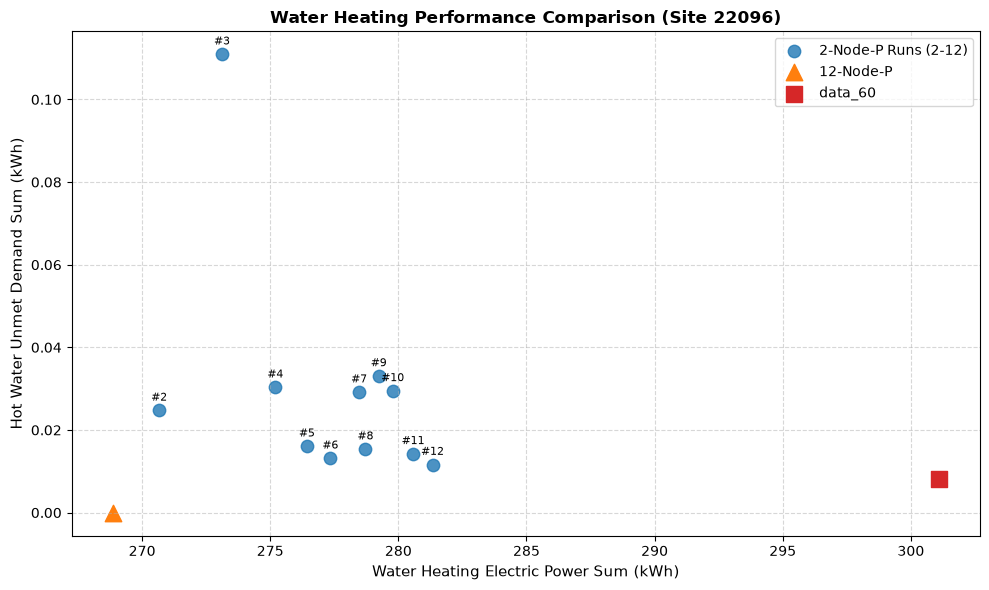

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

site = 22096

# 1. Load baseline datasets
data_60 = pd.read_csv(f"output_site_{site}_151(L)_60_120V.csv")
data_12_node = pd.read_csv(f"output_site_{site}_bisection_perfect_12_120V.csv")

# 2. Load 2-node datasets programmatically (2 through 12)
data_2_nodes = {}
for i in range(2, 13):
    data_2_nodes[i] = pd.read_csv(f"output_site_{site}_bisection_perfect_2_120V_{i}.csv")

# 3. Calculate metrics and compile into a Summary DataFrame
records = [
    {
        'Model': 'data_60',
        'Group': 'data_60',
        'Unmet Demand (kWh)': data_60['Hot Water Unmet Demand (kWh)'].sum(),
        'Electric Power (kWh)': data_60['Water Heating Electric Power (kWh)'].sum()
    },
    {
        'Model': '12_node',
        'Group': '12_node',
        'Unmet Demand (kWh)': data_12_node['Hot Water Unmet Demand (kWh)'].sum(),
        'Electric Power (kWh)': data_12_node['Water Heating Electric Power (kWh)'].sum()
    }
]

for node_id, df in data_2_nodes.items():
    records.append({
        'Model': f'2_node_{node_id}',
        'Group': '2_node',
        'Unmet Demand (kWh)': df['Hot Water Unmet Demand (kWh)'].sum(),
        'Electric Power (kWh)': df['Water Heating Electric Power (kWh)'].sum()
    })

summary_df = pd.DataFrame(records)

# Print tabular comparison of sums
print("=== Total Demand & Power Summary ===")
print(summary_df.to_string(index=False))

# 4. Generate Scatter Plot
plt.figure(figsize=(10, 6))

# Plot 2-node datasets
node_2_mask = summary_df['Group'] == '2_node'
plt.scatter(
    summary_df.loc[node_2_mask, 'Electric Power (kWh)'],
    summary_df.loc[node_2_mask, 'Unmet Demand (kWh)'],
    color='tab:blue',
    s=80,
    alpha=0.8,
    label='2-Node-P Runs (2-12)'
)

# Annotate each 2-node point
for idx, row in summary_df[node_2_mask].iterrows():
    plt.annotate(
        row['Model'].replace('2_node_', '#'),
        (row['Electric Power (kWh)'], row['Unmet Demand (kWh)']),
        textcoords="offset points",
        xytext=(0, 7),
        ha='center',
        fontsize=8
    )

# Plot 12-node point
node_12_mask = summary_df['Group'] == '12_node'
plt.scatter(
    summary_df.loc[node_12_mask, 'Electric Power (kWh)'],
    summary_df.loc[node_12_mask, 'Unmet Demand (kWh)'],
    color='tab:orange',
    s=140,
    marker='^',
    label='12-Node-P'
)

# Plot data_60 point
data_60_mask = summary_df['Group'] == 'data_60'
plt.scatter(
    summary_df.loc[data_60_mask, 'Electric Power (kWh)'],
    summary_df.loc[data_60_mask, 'Unmet Demand (kWh)'],
    color='tab:red',
    s=140,
    marker='s',
    label='data_60'
)

plt.title(f'Water Heating Performance Comparison (Site {site})', fontsize=12, fontweight='bold')
plt.xlabel('Water Heating Electric Power Sum (kWh)', fontsize=11)
plt.ylabel('Hot Water Unmet Demand Sum (kWh)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True)

plt.tight_layout()
plt.show()

In [33]:
data_2_nodes[1]

KeyError: 1

In [36]:
index = 3
unmets = data_2_nodes[index][data_60['Hot Water Unmet Demand (kWh)'] < data_2_nodes[index]['Hot Water Unmet Demand (kWh)']]
unmets

,Hot Water Outlet Temperature (C),Hot Water Unmet Demand (kWh),Water Heating Electric Power (kWh),Water Heating Heat Pump COP (-),Water Heating Mode,T_WH1,T_WH3,T_WH6,T_WH10,T_WH12,Setpoints,Draw Data
50597,39.498428,0.009299,0.007457,6.389904,Heat Pump On,39.498428,33.730053,25.909882,11.738857,7.371698,60.0,7.57082
50598,37.494421,0.013464,0.007381,6.468816,Heat Pump On,37.494421,32.496245,23.582958,11.107057,7.290806,60.0,3.78541
50599,36.646916,0.017192,0.007373,6.476996,Heat Pump On,36.646916,31.801434,22.538626,11.176820,7.346142,60.0,3.78541
50600,35.854256,0.020678,0.007367,6.482681,Heat Pump On,35.854256,31.046084,21.574174,11.312723,7.385013,60.0,3.78541
50608,35.045307,0.024236,0.007674,6.171030,Heat Pump On,35.045307,30.214895,21.652111,16.256474,8.426263,60.0,3.78541
122592,39.656444,0.003955,0.008500,5.396594,Heat Pump On,39.656444,34.721018,34.721018,26.383296,8.582909,60.0,3.78541
122598,38.487818,0.009095,0.008608,5.301874,Heat Pump On,38.487818,35.435078,35.435078,27.699269,8.975536,60.0,3.78541
122600,37.596458,0.013015,0.008537,5.363876,Heat Pump On,37.596458,35.628588,35.628588,26.594252,8.670907,60.0,3.78541


In [22]:
data_2_node_perfect[data_2_node_perfect['Hot Water Unmet Demand (kWh)'] > data_12_node['Hot Water Unmet Demand (kWh)']]

,Hot Water Outlet Temperature (C),Hot Water Unmet Demand (kWh),Water Heating Electric Power (kW),Water Heating Electric Energy (kWh),Water Heating Heat Pump COP (-),Water Heating Mode,T_WH1,T_WH3,T_WH6,T_WH10,T_WH12,Setpoints,Draw Data
2169,34.952274,0.097661,0.423870,0.007064,6.804788,Heat Pump On,36.453208,15.927386,9.633198,8.492810,7.142325,60.0,15.000
2305,36.034886,0.078792,0.424040,0.007067,6.801708,Heat Pump On,37.625956,15.432373,9.714642,8.526824,7.142327,60.0,15.000
2306,23.593172,0.295640,0.423906,0.007065,6.804123,Heat Pump On,25.371322,9.715096,9.701113,8.480241,7.142323,60.0,15.000
2307,12.841754,0.483028,0.423817,0.007064,6.805745,Heat Pump On,13.441003,9.717436,9.670757,8.473964,7.142321,60.0,15.000
2308,9.721273,0.537416,0.423766,0.007063,6.806670,Heat Pump On,9.722035,9.696848,9.628473,8.473948,7.142322,60.0,15.000
2309,9.713487,0.537552,0.423744,0.007062,6.807075,Heat Pump On,9.716966,9.675266,9.585500,8.473951,7.142323,60.0,15.000
2310,9.691271,0.537939,0.423738,0.007062,6.807183,Heat Pump On,9.695097,9.639297,9.562562,8.473956,7.142323,60.0,15.000
2311,9.663188,0.538428,0.423737,0.007062,6.807193,Heat Pump On,9.668783,9.596989,9.559880,8.473959,7.142323,60.0,15.000
2312,9.624460,0.539103,0.423737,0.007062,6.807193,Heat Pump On,9.630532,9.563687,9.559851,8.473959,7.142323,60.0,15.000
2313,9.586348,0.539767,0.423737,0.007062,6.807193,Heat Pump On,9.590855,9.550360,9.559852,8.473959,7.142323,60.0,15.000


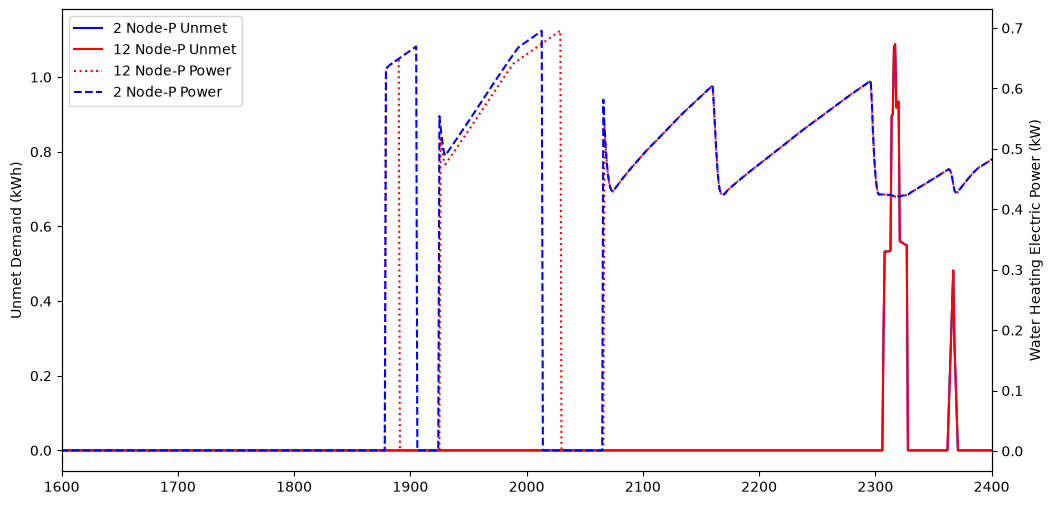

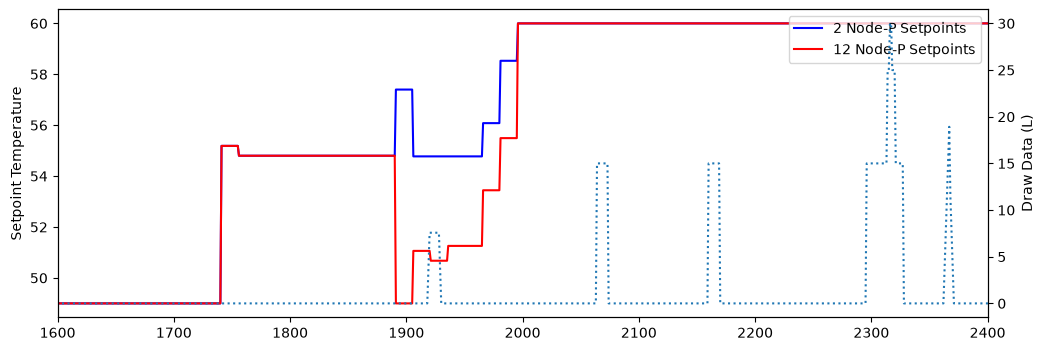

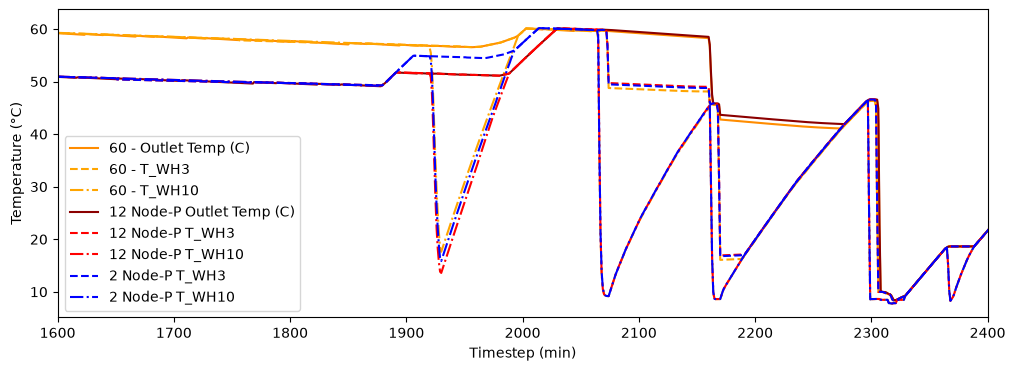

In [36]:
# read in data

site = 'sample'
import pandas as pd
data_60 = pd.read_csv(f"output_site_{site}_151(L)_60_120V.csv")
data_49 = pd.read_csv(f"output_site_{site}_151(L)_49_120V.csv")
#data_2_node = pd.read_csv(f"output_site_{site}_bisection_rolling_2_120V.csv")
data_2_node_perfect = pd.read_csv(f"output_site_{site}_bisection_perfect_2_120V_3_14_15.csv")
data_12_node = pd.read_csv(f"output_site_{site}_bisection_perfect_12_120V_3_14_15.csv")

import matplotlib.pyplot as plt

# Assuming 1 index step = 1 minute (unit='m')
# Use unit='s' for seconds, unit='h' for hours
#data_60.index = pd.to_timedelta(data_60.index, unit="m")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(data_2_node_perfect['Hot Water Unmet Demand (kWh)'], label='2 Node-P Unmet', color = 'blue')
ax.plot(data_12_node['Hot Water Unmet Demand (kWh)'], label='12 Node-P Unmet', color = 'red')
#ax.plot(data_60['Hot Water Unmet Demand (kWh)'], label='60 Unmet', color = 'orange')

#ax.plot(data_2_node['Hot Water Unmet Demand (kWh)'], label='2 Node Unmet', color = 'blue')

#ax.plot(data_2_node['Setpoints'], label='2 Node SP', color = 'blue')
#ax.plot(data_49['Hot Water Outlet Temperature (C)'], label='49 Setpoint')
#ax.axhline(y=49, color='gray', linestyle='--', label='Comfort')
#ax.axvline(x=120, linestyle='--', label='2 Hour Interval')
#ax.legend()
#ax.plot(data_60['Draw Data'], label = "Draw Data", linestyle = 'dotted')
ax2 = ax.twinx()
#ax2.plot(data_60['Water Heating Electric Power (kW)'], label='60 Power', linestyle = 'dashed', color = 'orange')
ax2.plot(data_12_node['Water Heating Electric Power (kW)'], label='12 Node-P Power', linestyle = 'dotted', color = 'red')
#ax2.plot(data_2_node['Water Heating Electric Power (kWh)'], label='2 Node Energy', linestyle = 'dashed', color = 'blue')
ax2.plot(data_2_node_perfect['Water Heating Electric Power (kW)'], label='2 Node-P Power', linestyle = 'dashed', color = 'blue')
#ax2.plot(data_49['Water Heating Electric Power (kWh)'], label='49', color='red')

#ax2.legend()
ax.set_ylabel('Unmet Demand (kWh)')
ax2.set_ylabel('Water Heating Electric Power (kW)')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2)
day = 5

lbound = day * 1400
ubound = lbound + 1400
lbound = 1600
ubound = 2400
plt.xlim(lbound, ubound)

# ==============================================================================
# Additional Snippet: 2-Node Perfect Setpoints Graph
# ==============================================================================
fig_sp, ax_sp = plt.subplots(figsize=(12, 4))
ax_sp.plot(data_2_node_perfect['Setpoints'], label='2 Node-P Setpoints', color='blue')
#ax_sp.plot(data_2_node['Setpoints'], label='2 Node Setpoints', color='blue')
ax_sp.plot(data_12_node['Setpoints'], label='12 Node-P Setpoints', color='red')
ax_draw = ax_sp.twinx()
ax_draw.plot(data_60['Draw Data'], label = "Draw Data", linestyle = 'dotted')
ax_draw.set_ylabel("Draw Data (L)")
ax_sp.set_ylabel('Setpoint Temperature')
ax_sp.set_xlim(lbound, ubound)
ax_sp.legend(loc='upper right')


# ==============================================================================
# Graph 3: Water Temperatures (Outlet, T_WH3, T_WH10) & Draw Data
# ==============================================================================
fig_temp, ax_temp = plt.subplots(figsize=(12, 4))

# Plot target temperatures (change dataframe names if T_WH3/T_WH10 belong to specific nodes)
ax_temp.plot(
    data_60["Hot Water Outlet Temperature (C)"],
    label="60 - Outlet Temp (C)",
    color="darkorange",
)
ax_temp.plot(data_60["T_WH3"], label="60 - T_WH3", color="orange", linestyle="--")
ax_temp.plot(data_60["T_WH10"], label="60 - T_WH10", color="orange", linestyle="-.")

ax_temp.plot(
    data_12_node["Hot Water Outlet Temperature (C)"],
    label="12 Node-P Outlet Temp (C)",
    color="darkred",
)
ax_temp.plot(data_12_node["T_WH3"], label="12 Node-P T_WH3", color="red", linestyle="--")
ax_temp.plot(data_12_node["T_WH10"], label="12 Node-P T_WH10", color="red", linestyle="-.")

# ax_temp.plot(
#     data_2_node_perfect["Hot Water Outlet Temperature (C)"],
#     label="2 Node-P Outlet Temp (C)",
#     color="darkblue",
# )
ax_temp.plot(data_2_node_perfect["T_WH3"], label="2 Node-P T_WH3", color="blue", linestyle="--")
ax_temp.plot(data_2_node_perfect["T_WH10"], label="2 Node-P T_WH10", color="blue", linestyle="-.")


ax_temp.set_ylabel("Temperature (°C)")
ax_temp.set_xlim(lbound, ubound)

# Combine legends for primary and secondary y-axes
lines_temp, labels_temp = ax_temp.get_legend_handles_labels()

ax_temp.legend()
ax_temp.set_xlabel("Timestep (min)")
plt.show()



In [192]:
filtered_60

,Hot Water Outlet Temperature (C),Hot Water Unmet Demand (kWh),Water Heating Electric Power (kWh),Water Heating Heat Pump COP (-),Water Heating Mode,T_WH1,T_WH3,T_WH6,T_WH10,T_WH12,Setpoints,Draw Data
105957,39.872383,0.006010,0.007182,6.677798,Heat Pump On,39.872383,25.660101,13.699944,9.809050,7.253631,60,7.57082
105958,35.528201,0.022112,0.007177,6.683426,Heat Pump On,35.528201,22.202840,13.062838,9.827891,7.243764,60,3.78541
124101,38.130911,0.010665,0.007383,6.466388,Heat Pump On,38.130911,26.391788,18.209852,11.964055,7.316512,60,3.78541
124109,36.161691,0.019326,0.007691,6.153776,Heat Pump On,36.161691,25.164605,19.004909,16.633566,8.377124,60,3.78541
124110,34.363740,0.027234,0.007672,6.172216,Heat Pump On,34.363740,24.070163,19.232263,16.898873,8.108619,60,3.78541
...,...,...,...,...,...,...,...,...,...,...,...,...
482569,40.225477,0.002904,0.007375,6.474396,Heat Pump On,40.225477,25.895522,15.660658,12.778832,7.532936,60,7.57082
482570,35.743121,0.021167,0.007340,6.511469,Heat Pump On,35.743121,22.668105,15.400661,12.117934,7.355714,60,3.78541
482590,33.393881,0.031500,0.007997,5.856951,Heat Pump On,33.393881,21.456348,21.143839,21.143839,10.181919,60,3.78541
482596,31.365973,0.040420,0.008116,5.744985,Heat Pump On,31.365973,22.688173,22.688173,22.688173,10.113260,60,3.78541


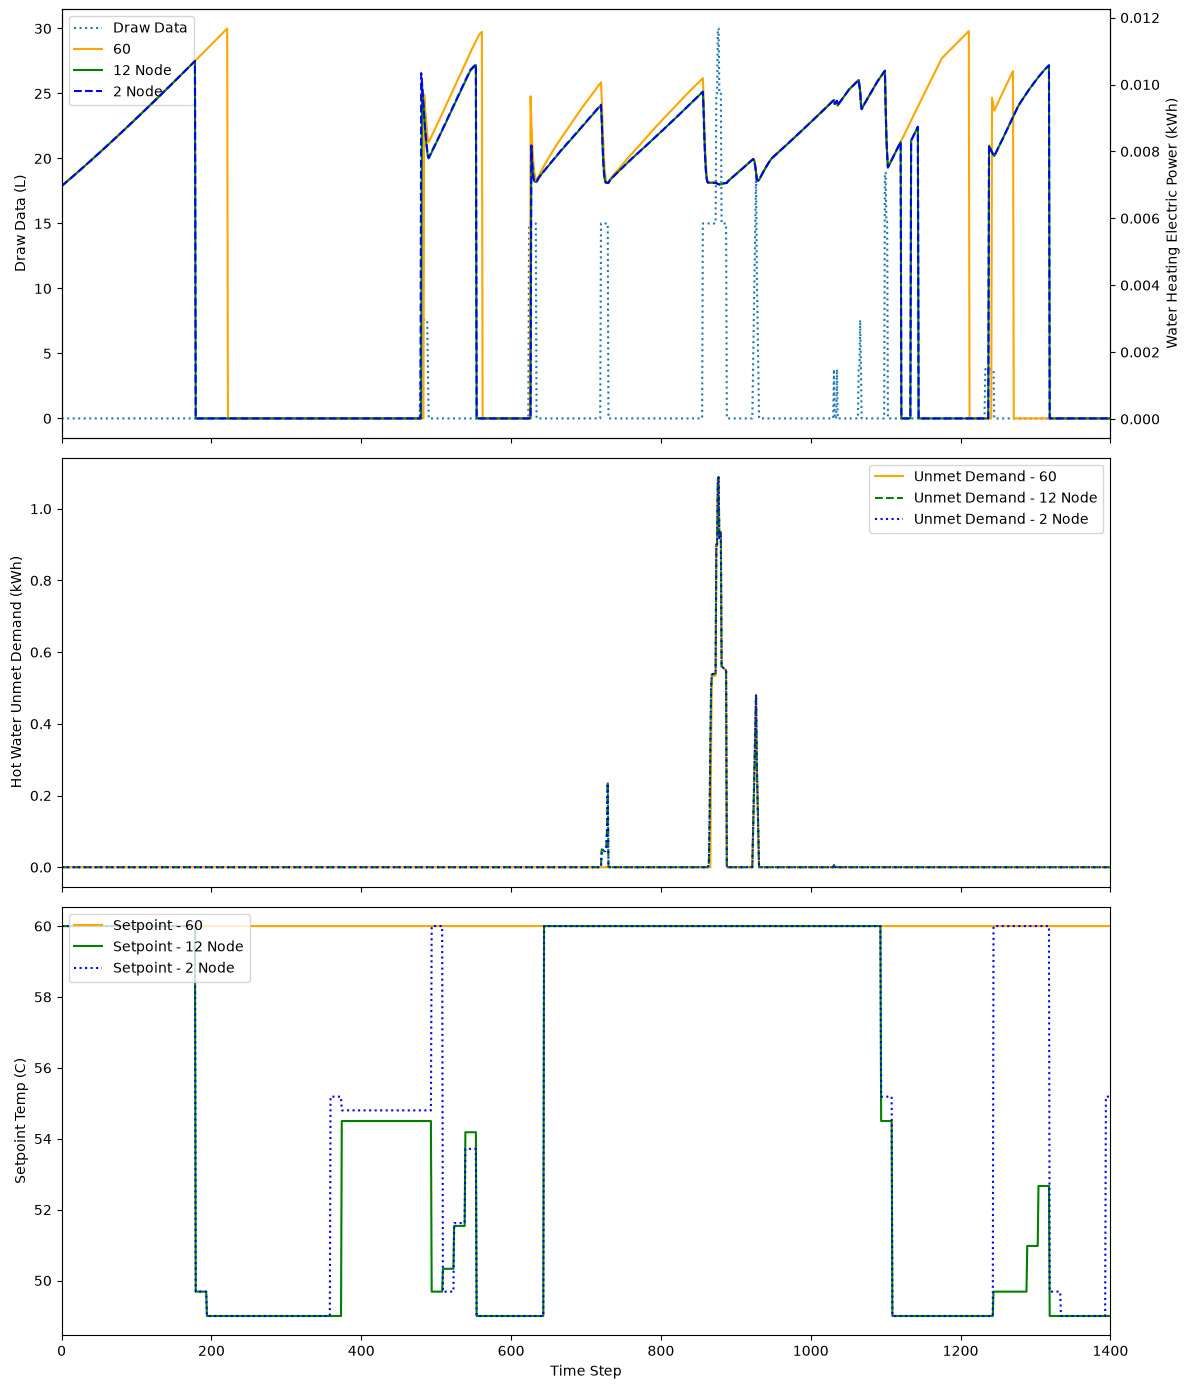

In [145]:
import matplotlib.pyplot as plt
import pandas as pd

# Read in data
data_60 = pd.read_csv("output_site_sample_151(L)_60_120V.csv")
data_49 = pd.read_csv("output_site_sample_151(L)_49_120V.csv")
data_2_node = pd.read_csv("output_site_sample_bisection_perfect_2_120V.csv")
data_12_node = pd.read_csv("output_site_sample_bisection_perfect_12_120V.csv")

data_2_node = pd.read_csv("output_site_sample_bisection_rolling_2_120V.csv")
data_12_node = pd.read_csv("output_site_sample_bisection_rolling_12_120V.csv")
data_1_node = pd.read_csv("output_site_sample_bisection_perfect_1_120V.csv")

# Create 3 vertically stacked subplots sharing the same x-axis
fig, (ax1, ax3, ax5) = plt.subplots(3, 1, figsize=(12, 14), sharex=True)

# ==================== GRAPH 1 ====================
ax1.plot(data_60["Draw Data"], label="Draw Data", linestyle="dotted")
ax2 = ax1.twinx()

ax2.plot(
    data_60["Water Heating Electric Power (kWh)"], label="60", color="orange"
)
ax2.plot(
    data_12_node["Water Heating Electric Power (kWh)"],
    label="12 Node",
    color="green",
)
ax2.plot(
    data_2_node["Water Heating Electric Power (kWh)"],
    label="2 Node",
    color="blue",
    linestyle="dashed",
)

ax1.set_ylabel("Draw Data (L)")
ax2.set_ylabel("Water Heating Electric Power (kWh)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# ==================== GRAPH 2 ====================
# Primary Y-axis: Unmet Demand
ax3.plot(
    data_60["Hot Water Unmet Demand (kWh)"],
    label="Unmet Demand - 60",
    color="orange",
)
ax3.plot(
    data_12_node["Hot Water Unmet Demand (kWh)"],
    label="Unmet Demand - 12 Node",
    color="green",
    linestyle="--",
)
ax3.plot(
    data_2_node["Hot Water Unmet Demand (kWh)"],
    label="Unmet Demand - 2 Node",
    color="blue",
    linestyle="dotted",
)
# ax3.plot(
#     data_49["Hot Water Unmet Demand (kWh)"],
#     label="Unmet Demand - 49",
#     color="red",
#     linestyle="--",
# )

# ax3.plot(
#     data_1_node["Hot Water Unmet Demand (kWh)"],
#     label="Unmet Demand - 1 Node",
#     color="yellow",
#     linestyle="--",
# )
ax3.set_ylabel("Hot Water Unmet Demand (kWh)")

# Secondary Y-axis: Outlet Temperature
# ax4 = ax3.twinx()
# ax4.plot(
#     data_60["Hot Water Outlet Temperature (C)"],
#     label="Temp - 60",
#     color="orange",
# )
# ax4.plot(
#     data_12_node["Hot Water Outlet Temperature (C)"],
#     label="Temp - 12 Node",
#     color="green",
# )
# ax4.plot(
#     data_2_node["Hot Water Outlet Temperature (C)"],
#     label="Temp - 2 Node",
#     color="blue",
# )
# ax4.plot(
#     data_49["Hot Water Outlet Temperature (C)"],
#     label="Temp - 49",
#     color="red",
# )
# ax4.set_ylabel("Hot Water Outlet Temperature (C)")

# Combine legends for graph 2
lines3, labels3 = ax3.get_legend_handles_labels()
#lines4, labels4 = ax4.get_legend_handles_labels()
#ax3.legend(lines3 + lines4, labels3 + labels4)
ax3.legend()

# ==================== GRAPH 3: SETPOINTS ====================
ax5.plot(
    data_60["Setpoints"],
    label="Setpoint - 60",
    color="orange",
)
ax5.plot(
    data_12_node["Setpoints"],
    label="Setpoint - 12 Node",
    color="green",

)
ax5.plot(
    data_2_node["Setpoints"],
    label="Setpoint - 2 Node",
    color="blue",
    linestyle="dotted",
)
# ax5.plot(
#     data_49["Setpoints"],
#     label="Setpoint - 49",
#     color="red",
#     linestyle="-.",
# )
# ax5.plot(
#     data_1_node["Setpoints"],
#     label="Setpoint - 1 Node",
#     color="yellow",
#     linestyle="-.",
# )
ax5.set_ylabel("Setpoint Temp (C)")
ax5.set_xlabel("Time Step")
ax5.legend(loc="upper left")

plt.xlim(0, 1400)
#plt.xlim(700, 900)

plt.tight_layout()
plt.show()

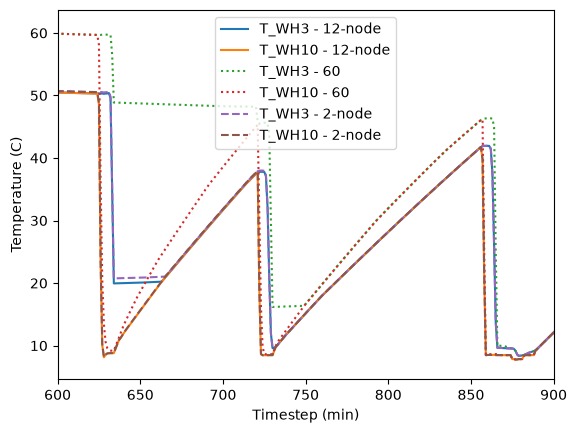

In [146]:
# data_1_node = pd.read_csv("output_site_sample_bisection_perfect_1_120V.csv")
# plt.plot(
#     data_1_node["T_WH3"],
#     label="T_WH3 - 1-node",

# )
# plt.plot(
#     data_1_node["T_WH10"],
#     label="T_WH10 - 1-node",

# ) 

plt.plot(
    data_12_node["T_WH3"],
    label="T_WH3 - 12-node",

)
plt.plot(
    data_12_node["T_WH10"],
    label="T_WH10 - 12-node",

) 

plt.plot(
    data_60["T_WH3"],
    label="T_WH3 - 60",
    linestyle="dotted",
)

plt.plot(
    data_60["T_WH10"],
    label="T_WH10 - 60",
    linestyle="dotted",
)


plt.plot(
    data_2_node["T_WH3"],
    label="T_WH3 - 2-node",
    linestyle="dashed",
)
plt.plot(
    data_2_node["T_WH10"],
    label="T_WH10 - 2-node",
    linestyle="dashed",
)


plt.xlim(600, 900)
plt.xlabel("Timestep (min)")
plt.ylabel("Temperature (C)")
plt.legend()
